# 05. How reliable are the GP uncertainty estimates?

**Purpose.** A GP gives a 95% prediction interval for every molecule. If the
intervals are honest, about 95% of experimental values should fall inside them.
This notebook counts how often that happens for each property, separately for
training and held-out (test) molecules.

**What this notebook produces**

* `Output_Data/uncertainty/coverage_table.csv`: percent of molecules inside the 95% interval.
* `Output_Data/uncertainty/95_CI_allProps.png` / `.pdf`: the coverage bar chart (600 dpi).
* `Output_Data/uncertainty/results_summary.md`: the results in plain sentences.
* `Output_Data/uncertainty/fig4_error_comparison.png` / `.pdf`: MAE and RMSE of the
  group-contribution baseline and of GC-GP for every property (main-text Fig. 4, 600 dpi),
  and `fig4_error_values.csv` with the plotted numbers.
* `Output_Data/uncertainty/gc_vs_gcgp_error_change.png` / `.pdf`: percent change in test MAE
  and RMSE from the Joback-Reid estimate to GC-GP, with paired bootstrap 95% intervals,
  and `gc_vs_gcgp_error_change.csv` with the plotted numbers.

**Inputs needed.** The pooled cross-validation predictions from
`04_Final_GCGP_CrossValidation.ipynb`. A copy of the predictions from an
earlier full run (the original Colab notebooks) is kept in
`Input_Data/reference_results/`, for comparison only. Fig. 4 also needs the matched baselines written by
`01_JRGC_Baseline.ipynb` in `Output_Data/jrgc_baseline/matched_cv/`.

## 1. Environment and setup

In [1]:
import sys
from pathlib import Path

# Find the repository root (the folder that contains src/gcgp) and make the
# shared code importable. This works whether Jupyter starts in notebooks/ or
# in the repository root.
repoRoot = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "gcgp").is_dir())
sys.path.insert(0, str(repoRoot / "src"))

import numpy as np
import pandas as pd

from gcgp.settings import (OUTPUT_DIR, REFERENCE_RESULTS_DIR, checkInputs, describeSetup,
                           outputFolder, setGlobalSeed)
from gcgp.properties import PROPERTY_ORDER
from gcgp.finalConfig import RUN_NAMES
from gcgp.metrics import coverageBySet
from gcgp.plotting import plotCoverageBars

setGlobalSeed()
outputDir = outputFolder("uncertainty")
pd.set_option("display.precision", 2)
print(describeSetup())

Run mode      : FULL
Input folder  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Input_Data
Output folder : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data
Curated data  : /Users/sghosh6/Research_Work/BioSci/AMINES_GCGP/gcgp-amines/Output_Data/curated_data
GP workers    : 1 (set GCGP_N_WORKERS to fit restarts in parallel)
Global seed   : 42


## 2. Load the cross-validation predictions

`predictionSource` picks where the predictions come from:

* `"pipeline"`: the files written by notebook 04 in `Output_Data/final_gcgp_cv/`.
* `"reference"`: the earlier Colab run, in `Input_Data/reference_results/`.

In [2]:
predictionSource = "pipeline"

sourceDirs = {
    "pipeline": lambda run: OUTPUT_DIR / "final_gcgp_cv" / run,
    "reference": lambda run: REFERENCE_RESULTS_DIR,
}

if predictionSource == "reference":
    checkInputs(("reference_results",))

predictionTables = {}
for code in PROPERTY_ORDER:
    runName = RUN_NAMES[code]
    path = sourceDirs[predictionSource](runName) / f"{runName}_all_cv_predictions.csv"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run notebook 04 first, "
                                "or set predictionSource = 'reference'.")
    predictionTables[code] = pd.read_csv(path)

{code: table.shape for code, table in predictionTables.items()}

{'Tb': (8860, 7),
 'Tm': (18390, 7),
 'Pc': (750, 7),
 'Vc': (690, 7),
 'Tc': (700, 7),
 'Hvap': (700, 7),
 'logP': (29780, 7)}

## 3. Coverage of the 95% intervals

A molecule is "inside" when |experimental − predicted| ≤ the 95% half-width.

With only about 70 test molecules for Pc, Vc, Tc and ΔHvap, the observed
coverage is itself uncertain. The last two columns give a 95% Wilson confidence
interval for the test coverage. If this interval does not contain 95%, the
difference from the target is unlikely to be chance.

In [3]:
def wilsonInterval(successes, n, z=1.96):
    """95% Wilson score interval for a proportion, in percent."""
    p = successes / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    halfWidth = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (centre - halfWidth), 100 * (centre + halfWidth)


rows = []
for code, table in predictionTables.items():
    cov = coverageBySet(table)
    low, high = wilsonInterval(round(cov["Test"] / 100 * cov["nTest"]), cov["nTest"])
    rows.append({"Property": code, "Train": cov["Train"], "Test": cov["Test"],
                 "nTestMolecules": cov["nTest"], "Test 95% CI low": low, "Test 95% CI high": high})

coverageDf = pd.DataFrame(rows).set_index("Property")
coverageDf.to_csv(outputDir / "coverage_table.csv")
coverageDf

,Train,Test,nTestMolecules,Test 95% CI low,Test 95% CI high
Property,,,,,
Tb,94.06,93.79,886,92.01,95.20
Tm,94.80,94.67,1839,93.55,95.61
Pc,95.26,89.33,75,80.34,94.50
Vc,95.01,92.75,69,84.13,96.87
Tc,93.17,90.00,70,80.77,95.07
Hvap,99.37,92.86,70,84.34,96.91
logP,98.37,94.19,2978,93.29,94.98


## 4. Coverage figure

Blue bars are training molecules, red bars are held-out test molecules. The
default uses a broken axis. Set `brokenAxis =
False` for a single continuous axis starting at 80% with a line at the 95%
target, which is easier to read.

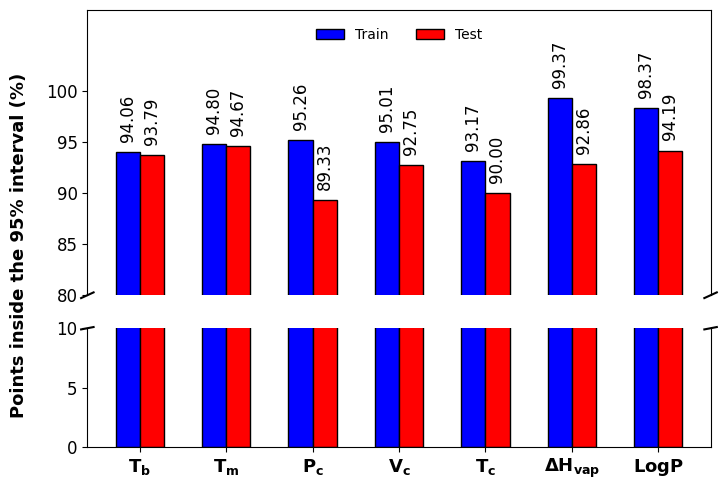

In [4]:
brokenAxis = True

labels = [r"$\mathbf{T_b}$", r"$\mathbf{T_m}$", r"$\mathbf{P_c}$", r"$\mathbf{V_c}$",
          r"$\mathbf{T_c}$", r"$\mathbf{\Delta H_{vap}}$", r"$\mathbf{LogP}$"]
plotCoverageBars(coverageDf.loc[PROPERTY_ORDER], labels,
                 savePath=outputDir / "95_CI_allProps.png", brokenAxis=brokenAxis)

## 5. Error comparison: group-contribution baseline and GC-GP (Fig. 4)

MAE (green) and RMSE (orange) for every property, for the baseline and for GC-GP.
Hatched bars are training (in-fold) predictions and solid bars are test (out-of-fold)
predictions. All models are scored on the same curated molecules and the same ten
folds, so the bars of a property can be compared between panels.

`fig4Panels` picks the panels, from left to right in the list and top to bottom in
the figure:

* `"raw"`: the raw GC estimate (Joback-Reid; Wildman-Crippen for log P), the baseline
  of main-text Fig. 2 and Table 2. The published group parameters are used as they are,
  with no parameter adjusted to these data, so there is no training set: MAE and RMSE
  (and R² in Table 2) compare the estimate with experiment for every curated molecule,
  and the panel has one set of bars. The original parameters were regressed on
  literature data that may include some of these molecules.
* `"linear"`: the linear recalibration `y = a·MW + b·y_GC + c` of notebook 01, with
  in-fold and out-of-fold bars like GC-GP.
* `"gcgp"`: the GC-GP predictions loaded in Section 2.

The default, `["raw", "gcgp"]`, matches main-text Fig. 4. All panels share one
horizontal scale. Errors are in the unit of each property (shown on the left), so
bars can be compared between panels for one property but not between properties.

The baseline values are recomputed with `calculateMetrics` from the prediction files of
notebook 01; the GC-GP values from the predictions of notebook 04. The cell stops with
an error if the GC-GP test RMSE differs from `final_cv_summary.csv` or if a baseline was
scored on different molecules.

In [5]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

from gcgp.metrics import calculateMetrics
from gcgp.plotting import finishFigure, savePlot
from gcgp.properties import PROPERTIES

fig4Panels = ["raw", "gcgp"]

MAE_COLOR = "green"
RMSE_COLOR = "orange"
PANEL_TITLES = {"raw": "Joback-Reid GC estimate (log P: Wildman-Crippen)",
                "linear": "Linear recalibration of the GC estimate",
                "gcgp": "GC-GP"}
matchedDir = OUTPUT_DIR / "jrgc_baseline" / "matched_cv"
finalSummaryPath = OUTPUT_DIR / "final_gcgp_cv" / "final_cv_summary.csv"


def splitMetrics(table, trueCol, predCol):
    # MAE and RMSE of the training (in-fold) and test (out-of-fold) rows of a prediction table.
    out = {}
    for setName in ["Train", "Test"]:
        part = table[table["Set"] == setName]
        if len(part):
            stats = calculateMetrics(part[trueCol], part[predCol])
            out[setName] = {"MAE": stats["MAE"], "RMSE": stats["RMSE"], "N": len(part)}
    return out


def loadPanelMetrics(model, code):
    info, runName = PROPERTIES[code], RUN_NAMES[code]
    if model == "gcgp":
        return splitMetrics(predictionTables[code], info["xLabel"], info["yLabel"])
    fileName = {"raw": f"{runName}_rawGC_predictions.csv",
                "linear": f"{runName}_linear_all_cv_predictions.csv"}[model]
    path = matchedDir / runName / fileName
    if not path.is_file():
        raise FileNotFoundError(f"{path} not found. Run notebooks/01_JRGC_Baseline.ipynb first.")
    table = pd.read_csv(path, float_precision="round_trip")
    gcgpTest = predictionTables[code].query("Set == 'Test'")
    baseTest = table.query("Set == 'Test'")
    assert len(baseTest) == len(gcgpTest), (
        f"{code}: {model} baseline has {len(baseTest)} test molecules, GC-GP {len(gcgpTest)}. "
        "Rerun notebook 01 after notebook 04, and use predictionSource = 'pipeline'.")
    if "RowIndex" in gcgpTest:
        assert np.array_equal(np.sort(baseTest["RowIndex"].to_numpy()), np.sort(gcgpTest["RowIndex"].to_numpy())), \
            f"{code}: {model} baseline and GC-GP were scored on different molecules"
    return splitMetrics(table, info["xLabel"], info["yLabel"])


if predictionSource != "pipeline":
    print("Fig. 4 uses the notebook 04 predictions; set predictionSource = 'pipeline' and rerun Section 2.")
else:
    rows = []
    for model in fig4Panels:
        for code in PROPERTY_ORDER:
            for setName, values in loadPanelMetrics(model, code).items():
                rows.append({"Panel": model, "Property": code, "Unit": PROPERTIES[code]["unit"],
                             "Set": setName, "N": values["N"], "MAE": values["MAE"], "RMSE": values["RMSE"]})
    fig4Df = pd.DataFrame(rows)

    if finalSummaryPath.is_file() and "gcgp" in fig4Panels:
        finalSummary = pd.read_csv(finalSummaryPath).set_index("Property")
        for code in PROPERTY_ORDER:
            plotted = fig4Df.query("Panel == 'gcgp' and Property == @code and Set == 'Test'")["RMSE"].iloc[0]
            expected = finalSummary.loc[RUN_NAMES[code], "Overall_Test_RMSE"]
            assert np.isclose(plotted, expected), f"{code}: GC-GP test RMSE {plotted} differs from {expected}"

    fig4Df.to_csv(outputDir / "fig4_error_values.csv", index=False)
    display(fig4Df.pivot_table(index="Property", columns=["Panel", "Set"], values=["MAE", "RMSE"])
            .reindex(PROPERTY_ORDER))

MAE                 RMSE               
Panel      gcgp           raw   gcgp            raw
Set        Test  Train   Test   Test  Train    Test
Property                                           
Tb        20.78  20.51  25.80  26.57  26.27   32.85
Tm        43.59  42.75  77.82  55.00  54.07  102.30
Pc         3.59   2.43   3.37   5.55   3.86    5.43
Vc        13.23  11.92  12.98  18.12  15.20   20.59
Tc        24.86  22.90  23.41  32.18  29.54   30.36
Hvap       1.58   0.94   1.94   1.96   1.18    2.40
logP       0.42   0.20   0.47   0.67   0.33    0.75

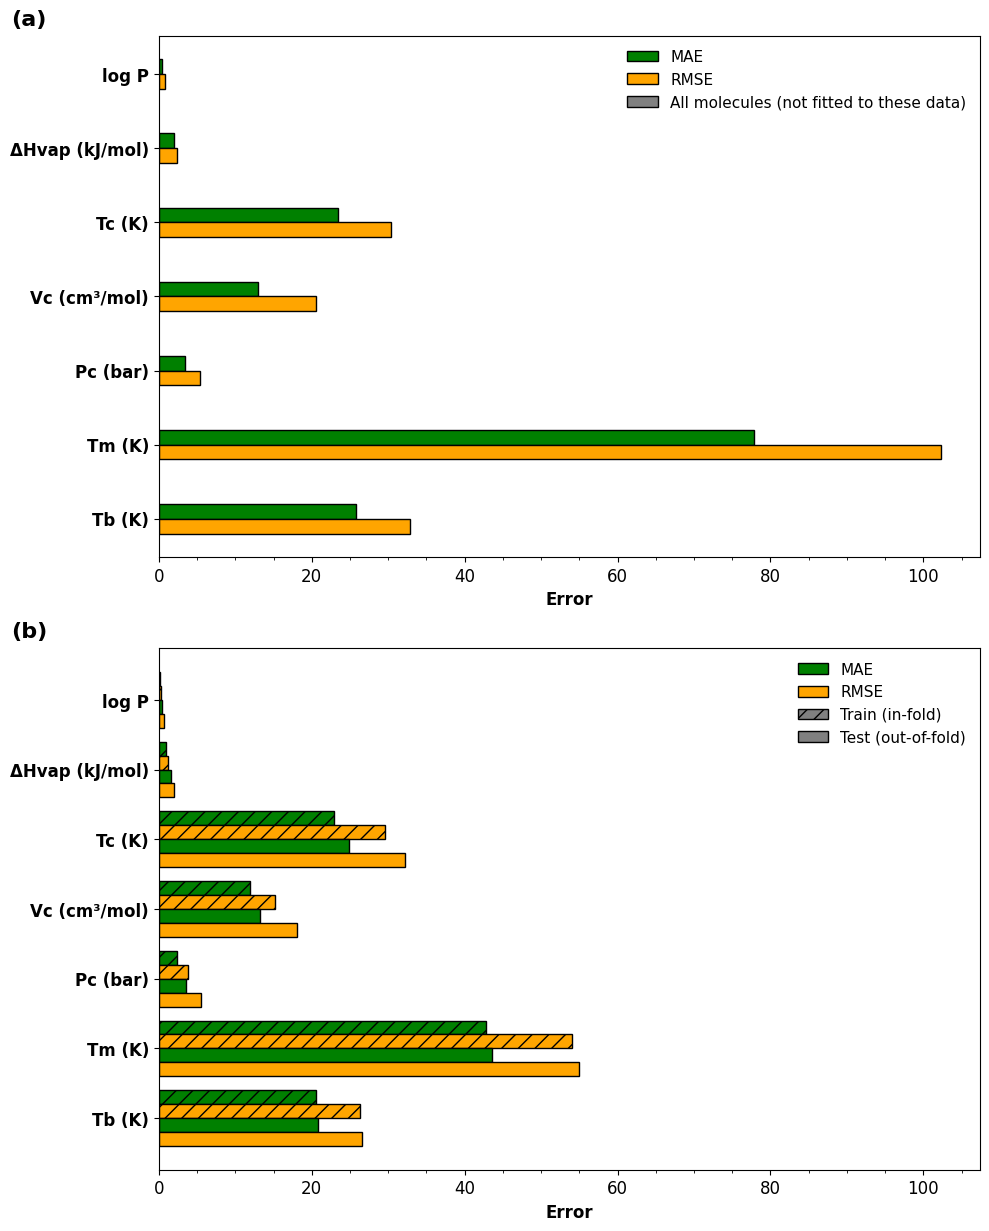

In [6]:
def plotErrorPanel(ax, panelDf, title, xMax, fontsize=12):
    # Horizontal MAE/RMSE bars per property; hatched = training, solid = test.
    barHeight = 0.2
    y = np.arange(len(PROPERTY_ORDER))
    for i, code in enumerate(PROPERTY_ORDER):
        part = panelDf[panelDf["Property"] == code].set_index("Set")
        slots = [("Train", "MAE", MAE_COLOR, "//"), ("Train", "RMSE", RMSE_COLOR, "//"),
                 ("Test", "MAE", MAE_COLOR, None), ("Test", "RMSE", RMSE_COLOR, None)]
        slots = [slot for slot in slots if slot[0] in part.index]
        for k, (setName, metric, color, hatch) in enumerate(slots):
            offset = ((len(slots) - 1) / 2 - k) * barHeight
            ax.barh(y[i] + offset, part.loc[setName, metric], height=barHeight, color=color,
                    hatch=hatch, edgecolor="black")
    labels = []
    for code in PROPERTY_ORDER:
        unit = PROPERTIES[code]["unit"]
        labels.append(f"{PROPERTIES[code]['label']} ({unit})" if unit else PROPERTIES[code]["label"])
    ax.set_yticks(y)
    ax.set_yticklabels(labels, fontsize=fontsize, fontweight="bold")
    ax.set_xlim(0, xMax)
    ax.set_xlabel("Error", fontsize=fontsize, fontweight="bold")
    ax.tick_params(axis="x", labelsize=fontsize)
    ax.minorticks_on()
    ax.tick_params(axis="y", which="minor", left=False)


if predictionSource == "pipeline":
    xMax = 1.05 * fig4Df[["MAE", "RMSE"]].to_numpy().max()
    fig, axes = plt.subplots(len(fig4Panels), 1, figsize=(10, 6.2 * len(fig4Panels)), squeeze=False)
    for panel, (ax, model) in enumerate(zip(axes[:, 0], fig4Panels)):
        plotErrorPanel(ax, fig4Df[fig4Df["Panel"] == model], PANEL_TITLES[model], xMax)
        ax.text(-0.18, 1.02, f"({chr(ord('a') + panel)})", transform=ax.transAxes,
                fontsize=16, fontweight="bold")
        handles = [Patch(facecolor=MAE_COLOR, edgecolor="black", label="MAE"),
                   Patch(facecolor=RMSE_COLOR, edgecolor="black", label="RMSE"),
                   Patch(facecolor="grey", edgecolor="black", hatch="//", label="Train (in-fold)"),
                   Patch(facecolor="grey", edgecolor="black", label="Test (out-of-fold)")]
        if model == "raw":
            handles = handles[:2] + [Patch(facecolor="grey", edgecolor="black", label="All molecules (not fitted to these data)")]
        ax.legend(handles=handles, loc="upper right", fontsize=11)
    fig.tight_layout()
    savePlot(fig, outputDir / "fig4_error_comparison.png")
    finishFigure(fig, show=True)

## 6. Direct comparison: how much GC-GP changes the Joback-Reid error

Fig. 4 shows the errors of the two methods in separate panels and in the unit of each
property, so a drop of tens of kelvin in Tm and a drop of less than 0.1 in log P are
hard to compare by eye.
This figure puts both methods on one axis: for every property it shows the percent
change in test MAE (green) and test RMSE (orange) when the Joback-Reid estimate
(Wildman-Crippen for log P) is replaced by the GC-GP prediction,

`change = 100 × (error_GCGP − error_GC) / error_GC`.

Bars to the left of zero mean GC-GP has the lower error. Only out-of-fold (test)
GC-GP predictions are used, paired with the GC estimate of the same molecule, so both
errors come from exactly the same molecules. The text on the right gives the test RMSE
of the two methods in the unit of the property.

The error bars are 95% intervals from a paired bootstrap over molecules (`N_BOOT`
resamples, seed `BOOT_SEED`; the same settings as Table 2). A faded bar means the
interval includes zero, so that change is not distinguishable from no change. Table 2
also requires a Wilcoxon test before calling a difference significant; this figure
shows only the bootstrap interval. Properties are sorted from the largest RMSE
reduction to the smallest.

In [7]:
N_BOOT = 2000
BOOT_SEED = 0
METRIC_FUNCTIONS = {"MAE": lambda e: np.abs(e).mean(axis=-1),
                    "RMSE": lambda e: np.sqrt((e ** 2).mean(axis=-1))}


def pairedTestErrors(code):
    # Errors of the GC estimate and of the GC-GP test prediction for the same molecules.
    info, runName = PROPERTIES[code], RUN_NAMES[code]
    path = matchedDir / runName / f"{runName}_rawGC_predictions.csv"
    if not path.is_file():
        raise FileNotFoundError(f"{path} not found. Run notebooks/01_JRGC_Baseline.ipynb first.")
    gcTable = pd.read_csv(path, float_precision="round_trip").query("Set == 'Test'")
    gpTable = predictionTables[code].query("Set == 'Test'")
    assert "RowIndex" in gpTable, "GC-GP predictions need RowIndex; use predictionSource = 'pipeline'."
    merged = gcTable.merge(gpTable, on="RowIndex", suffixes=("_gc", "_gp"), validate="one_to_one")
    assert len(merged) == len(gcTable) == len(gpTable), f"{code}: the two methods cover different molecules"
    xLabel, yLabel = info["xLabel"], info["yLabel"]
    assert np.allclose(merged[f"{xLabel}_gc"], merged[f"{xLabel}_gp"]), f"{code}: experimental values differ"
    experimental = merged[f"{xLabel}_gc"].to_numpy()
    return experimental - merged[f"{yLabel}_gc"].to_numpy(), experimental - merged[f"{yLabel}_gp"].to_numpy()


def errorChange(errGc, errGp, seed=BOOT_SEED):
    # Percent change of MAE and RMSE from GC to GC-GP, with a paired bootstrap 95% interval.
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(errGc), size=(N_BOOT, len(errGc)))
    out = {}
    for metric, func in METRIC_FUNCTIONS.items():
        gc, gp = func(errGc), func(errGp)
        bootGc, bootGp = func(errGc[idx]), func(errGp[idx])
        bootChange = 100 * (bootGp - bootGc) / bootGc
        out[metric] = {"GC": gc, "GCGP": gp, "Change_%": 100 * (gp - gc) / gc,
                       "CI_low_%": np.percentile(bootChange, 2.5), "CI_high_%": np.percentile(bootChange, 97.5)}
    return out


if predictionSource != "pipeline":
    print("This comparison uses the notebook 04 predictions; set predictionSource = 'pipeline' and rerun Section 2.")
else:
    rows = []
    for code in PROPERTY_ORDER:
        errGc, errGp = pairedTestErrors(code)
        for metric, values in errorChange(errGc, errGp).items():
            rows.append({"Property": code, "Unit": PROPERTIES[code]["unit"], "Metric": metric,
                         "N": len(errGc), **values})
    changeDf = pd.DataFrame(rows)
    changeDf["CI_excludes_0"] = (changeDf["CI_low_%"] > 0) | (changeDf["CI_high_%"] < 0)

    # The same numbers as Fig. 4 and Table 2.
    if "fig4Df" in globals():
        for panel, column in [("raw", "GC"), ("gcgp", "GCGP")]:
            if panel in set(fig4Df["Panel"]):
                for metric in METRIC_FUNCTIONS:
                    expected = fig4Df.query("Panel == @panel and Set == 'Test'").set_index("Property")[metric]
                    plotted = changeDf.query("Metric == @metric").set_index("Property")[column]
                    assert np.allclose(plotted, expected.loc[plotted.index]), f"{panel} {metric} differs from Fig. 4"

    changeDf.to_csv(outputDir / "gc_vs_gcgp_error_change.csv", index=False)
    display(changeDf.round(3))

,Property,Unit,Metric,N,GC,GCGP,Change_%,CI_low_%,CI_high_%,CI_excludes_0
0,Tb,K,MAE,886,25.80,20.78,-19.45,-22.94,-15.76,True
1,Tb,K,RMSE,886,32.85,26.57,-19.14,-22.53,-15.75,True
2,Tm,K,MAE,1839,77.82,43.59,-43.99,-46.39,-41.33,True
3,Tm,K,RMSE,1839,102.30,55.00,-46.24,-48.57,-43.65,True
4,Pc,bar,MAE,75,3.37,3.59,6.58,-2.14,19.26,False
5,Pc,bar,RMSE,75,5.43,5.55,2.26,-3.19,11.80,False
6,Vc,cm³/mol,MAE,69,12.98,13.23,1.96,-7.32,12.96,False
7,Vc,cm³/mol,RMSE,69,20.59,18.12,-12.00,-22.67,7.94,False
8,Tc,K,MAE,70,23.41,24.86,6.22,0.40,12.96,True
9,Tc,K,RMSE,70,30.36,32.18,6.01,0.59,13.06,True


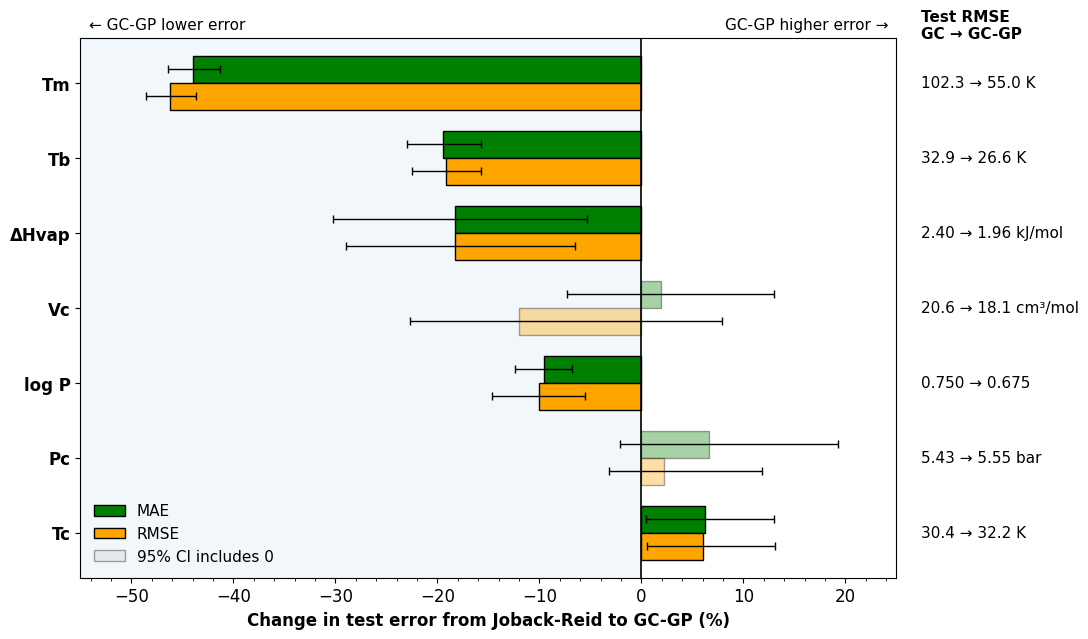

In [8]:
def formatValue(value):
    # Three significant figures are enough for the annotations.
    return f"{value:.3f}" if abs(value) < 1 else f"{value:.2f}" if abs(value) < 10 else f"{value:.1f}"


def plotErrorChange(ax, changeDf, fontsize=12):
    barHeight = 0.36
    rmse = changeDf.query("Metric == 'RMSE'").set_index("Property")
    order = rmse["Change_%"].sort_values(ascending=False).index.tolist()
    y = np.arange(len(order))
    for i, code in enumerate(order):
        for metric, color, offset in [("MAE", MAE_COLOR, barHeight / 2), ("RMSE", RMSE_COLOR, -barHeight / 2)]:
            row = changeDf.query("Property == @code and Metric == @metric").iloc[0]
            ax.barh(y[i] + offset, row["Change_%"], height=barHeight, color=color, edgecolor="black",
                    alpha=1.0 if row["CI_excludes_0"] else 0.35)
            ax.errorbar(row["Change_%"], y[i] + offset,
                        xerr=[[row["Change_%"] - row["CI_low_%"]], [row["CI_high_%"] - row["Change_%"]]],
                        fmt="none", ecolor="black", capsize=3, lw=1)
    lows, highs = changeDf["CI_low_%"].min(), changeDf["CI_high_%"].max()
    xMin, xMax = 5 * np.floor((lows - 3) / 5), 5 * np.ceil((max(highs, 0) + 3) / 5)
    ax.set_xlim(xMin, xMax)
    ax.axvspan(xMin, 0, color="tab:blue", alpha=0.06, zorder=0)
    ax.axvline(0, color="black", lw=1.2)
    ax.text(0.01, 1.01, "← GC-GP lower error", transform=ax.transAxes, fontsize=fontsize - 1, ha="left", va="bottom")
    ax.text(0.99, 1.01, "GC-GP higher error →", transform=ax.transAxes, fontsize=fontsize - 1, ha="right", va="bottom")

    ax.set_yticks(y)
    ax.set_yticklabels([PROPERTIES[code]["label"] for code in order], fontsize=fontsize, fontweight="bold")
    ax.set_ylim(-0.6, len(order) - 0.4)
    ax.set_xlabel("Change in test error from Joback-Reid to GC-GP (%)", fontsize=fontsize, fontweight="bold")
    ax.tick_params(axis="x", labelsize=fontsize)
    ax.minorticks_on()
    ax.tick_params(axis="y", which="minor", left=False)

    # Test RMSE of both methods, in the unit of the property, to the right of the axes.
    transform = ax.get_yaxis_transform()
    ax.text(1.03, len(order) - 0.45, "Test RMSE\nGC → GC-GP", transform=transform, fontsize=fontsize - 1,
            fontweight="bold", va="bottom")
    for i, code in enumerate(order):
        unit = PROPERTIES[code]["unit"]
        label = f"{formatValue(rmse.loc[code, 'GC'])} → {formatValue(rmse.loc[code, 'GCGP'])}"
        ax.text(1.03, y[i], f"{label} {unit}".strip(), transform=transform, fontsize=fontsize - 1, va="center")


if predictionSource == "pipeline":
    fig, ax = plt.subplots(figsize=(11, 6.5))
    plotErrorChange(ax, changeDf)
    handles = [Patch(facecolor=MAE_COLOR, edgecolor="black", label="MAE"),
               Patch(facecolor=RMSE_COLOR, edgecolor="black", label="RMSE"),
               Patch(facecolor="lightgrey", edgecolor="black", alpha=0.35, label="95% CI includes 0")]
    ax.legend(handles=handles, loc="lower left", fontsize=11)
    fig.tight_layout()
    savePlot(fig, outputDir / "gc_vs_gcgp_error_change.png")
    finishFigure(fig, show=True)

## 7. Summary of the results

Written from the coverage table above. Training coverage above 95% is expected
for a GP, because the model has already seen those molecules. Test coverage is
the number that matters, judged against its Wilson interval.

In [9]:
from gcgp.narrative import describeCoverage, showAndSave

showAndSave(describeCoverage(coverageDf), outputDir / f"results_summary_{predictionSource}.md");

## Coverage of the 95% prediction intervals: results

- **Tb**: 93.8% of 886 test molecules inside the interval (95% CI 92.0–95.2%), consistent with 95%; training coverage 94.1%.
- **Tm**: 94.7% of 1839 test molecules inside the interval (95% CI 93.5–95.6%), consistent with 95%; training coverage 94.8%.
- **Pc**: 89.3% of 75 test molecules inside the interval (95% CI 80.3–94.5%), below 95% (intervals too narrow); training coverage 95.3%.
- **Vc**: 92.8% of 69 test molecules inside the interval (95% CI 84.1–96.9%), consistent with 95%; training coverage 95.0%.
- **Tc**: 90.0% of 70 test molecules inside the interval (95% CI 80.8–95.1%), consistent with 95%; training coverage 93.2%.
- **ΔHvap**: 92.9% of 70 test molecules inside the interval (95% CI 84.3–96.9%), consistent with 95%; training coverage 99.4%.
- **log P**: 94.2% of 2978 test molecules inside the interval (95% CI 93.3–95.0%), below 95% (intervals too narrow); training coverage 98.4%.

Test coverage is significantly below 95% for Pc, log P.
